# ThyroPredict — AI-Based Thyroid Abnormality Prediction System
## Exploratory Data Analysis, Preprocessing & Multi-Model Machine Learning Pipeline

### Project Overview
Thyroid diseases (hypothyroidism and hyperthyroidism) affect hundreds of millions of individuals worldwide. Thyroid hormones (Thyroxine/T4 and Triiodothyronine/T3) regulate metabolic rate, cardiac function, and general energy homeostasis, while Thyroid Stimulating Hormone (TSH) produced by the pituitary gland regulates thyroid gland hormone synthesis.

This notebook builds a complete, leak-free, educational Machine Learning workflow using the standard **UCI Thyroid Disease (Hypothyroid) Benchmark Dataset** to predict whether patient clinical records indicate a **Normal** condition or a **Thyroid Abnormality**.

---
> **Important Educational Disclaimer**:
> This notebook is an educational machine-learning prototype and is not intended to provide medical diagnosis, treatment, or clinical advice. Predictions should not be used as a substitute for evaluation by a qualified healthcare professional.
---

## Section 1 — Import Libraries
We import essential libraries for data manipulation, numerical computing, visualization, and machine learning pipelines.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Scikit-Learn tools
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
pd.set_option('display.max_columns', 35)

print("Libraries imported successfully!")

Libraries imported successfully!


## Section 2 — Load Dataset
We load `data/thyroid.csv` (UCI Thyroid Disease / Hypothyroid dataset). We inspect the dataset's dimensions, data types, summary statistics, and initial rows.

In [2]:
data_path = os.path.join('..', 'data', 'thyroid.csv')
if not os.path.exists(data_path):
    data_path = os.path.join('data', 'thyroid.csv')

df_raw = pd.read_csv(data_path)

print(f"Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print(f"Total Columns: {list(df_raw.columns)}")
df_raw.head()

Dataset Shape: 3772 rows, 30 columns
Total Columns: ['age', 'sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_medication', 'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych', 'TSH_measured', 'TSH', 'T3_measured', 'T3', 'TT4_measured', 'TT4', 'T4U_measured', 'T4U', 'FTI_measured', 'FTI', 'TBG_measured', 'TBG', 'referral_source', 'Class']


,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,query_hyperthyroid,lithium,goitre,tumor,hypopituitary,psych,TSH_measured,TSH,T3_measured,T3,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,Class
0,41.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,1.30,t,2.5,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,negative
1,23.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,4.10,t,2.0,t,102.0,f,NaN,f,NaN,f,NaN,other,negative
2,46.0,M,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.98,f,NaN,t,109.0,t,0.91,t,120.0,f,NaN,other,negative
3,70.0,F,t,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.16,t,1.9,t,175.0,f,NaN,f,NaN,f,NaN,other,negative
4,70.0,F,f,f,f,f,f,f,f,f,f,f,f,f,f,f,t,0.72,t,1.2,t,61.0,t,0.87,t,70.0,f,NaN,SVI,negative


In [3]:
# Dataset Information and Data Types
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3772 entries, 0 to 3771
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        3771 non-null   float64
 1   sex                        3622 non-null   object 
 2   on_thyroxine               3772 non-null   object 
 3   query_on_thyroxine         3772 non-null   object 
 4   on_antithyroid_medication  3772 non-null   object 
 5   sick                       3772 non-null   object 
 6   pregnant                   3772 non-null   object 
 7   thyroid_surgery            3772 non-null   object 
 8   I131_treatment             3772 non-null   object 
 9   query_hypothyroid          3772 non-null   object 
 10  query_hyperthyroid         3772 non-null   object 
 11  lithium                    3772 non-null   object 
 12  goitre                     3772 non-null   object 
 13  tumor                      3772 non-null   objec

In [4]:
# Statistical Summary for Numerical Features
df_raw.describe()

,age,TSH,T3,TT4,T4U,FTI,TBG
count,3771.000000,3403.000000,3003.000000,3541.000000,3385.000000,3387.000000,0.0
mean,51.735879,5.086766,2.013500,108.319345,0.995000,110.469649,NaN
std,20.084958,24.521470,0.827434,35.604248,0.195457,33.089698,NaN
min,1.000000,0.005000,0.050000,2.000000,0.250000,2.000000,NaN
25%,36.000000,0.500000,1.600000,88.000000,0.880000,93.000000,NaN
50%,54.000000,1.400000,2.000000,103.000000,0.980000,107.000000,NaN
75%,67.000000,2.700000,2.400000,124.000000,1.080000,124.000000,NaN
max,455.000000,530.000000,10.600000,430.000000,2.320000,395.000000,NaN


## Section 3 — Data Cleaning
Data cleaning is performed with careful clinical and statistical rationale:
1. **Empty Columns (`TBG`)**: The `TBG` (Thyroxine-Binding Globulin) column has 100% missing values (0 non-null records) in this dataset, and `TBG_measured` is uniformly 'f'. Both are dropped.
2. **Administrative Metadata (`referral_source`)**: Information like hospital referral code (`SVHC`, `SVI`, etc.) is administrative routing data rather than patient pathophysiology. It is removed to avoid non-generalizable bias.
3. **Redundant Indicator Flags (`*_measured`)**: Columns like `TSH_measured`, `T3_measured`, etc. indicate whether the test was performed. In practice and prediction, the test value itself is the direct indicator, so these redundant binary flags are dropped.
4. **Biologically Impossible Outliers**: A known transcription typo in the UCI dataset shows a record with `age = 455`. This value is replaced with `NaN` so it is mathematically imputed via the median during preprocessing.
5. **Duplicate Records**: Duplicate entries are identified and removed.

In [5]:
df_clean = df_raw.copy()

# 1. Missing value percentages
print("Missing values per column in raw dataset:")
missing = df_clean.isnull().sum()
missing_pct = (missing / len(df_clean)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Percentage (%)': missing_pct.round(2)})
display(missing_df[missing_df['Missing Count'] > 0])

# 2. Drop 100% empty TBG and administrative/redundant measurement columns
cols_to_drop = [
    'TBG', 'TBG_measured', 'referral_source',
    'TSH_measured', 'T3_measured', 'TT4_measured', 'T4U_measured', 'FTI_measured'
]
df_clean = df_clean.drop(columns=[col for col in cols_to_drop if col in df_clean.columns])

# 3. Clean biologically impossible age outlier (age > 100)
age_outliers = (df_clean['age'] > 100).sum()
print(f"Found {age_outliers} record(s) with age > 100. Correcting to NaN...")
df_clean.loc[df_clean['age'] > 100, 'age'] = np.nan

# 4. Remove duplicate records
n_dups = df_clean.duplicated().sum()
print(f"Found {n_dups} duplicate record(s). Removing duplicates...")
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print(f"Cleaned dataset shape: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns")

Missing values per column in raw dataset:


,Missing Count,Percentage (%)
age,1,0.03
sex,150,3.98
TSH,369,9.78
T3,769,20.39
TT4,231,6.12
T4U,387,10.26
FTI,385,10.21
TBG,3772,100.00


Found 1 record(s) with age > 100. Correcting to NaN...
Found 61 duplicate record(s). Removing duplicates...
Cleaned dataset shape: 3711 rows, 22 columns


## Section 4 — Target Variable Analysis
The dataset contains the clinical diagnostic label `Class`:
- `negative`: Normal patient thyroid panel (no abnormality).
- `compensated_hypothyroid`: Early/mild thyroid dysfunction where elevated TSH compensates to keep thyroid hormone levels in range.
- `primary_hypothyroid`: Severe thyroid dysfunction where the thyroid gland fails, resulting in high TSH and low T4.
- `secondary_hypothyroid`: Pituitary gland deficiency causing abnormal thyroid stimulation (only 2 samples in the entire dataset).

To create a balanced, reliable binary classification problem suitable for clinical screening:
- **`Normal` (0)**: `negative`
- **`Thyroid Abnormality` (1)**: `compensated_hypothyroid`, `primary_hypothyroid`, `secondary_hypothyroid`

In [6]:
print("Original target categories count:")
print(df_clean['Class'].value_counts())

# Binary mapping
df_clean['target'] = (df_clean['Class'] != 'negative').astype(int)
df_clean['target_label'] = df_clean['target'].map({0: 'Normal', 1: 'Thyroid Abnormality'})

print("\nBinary Target Distribution:")
target_counts = df_clean['target_label'].value_counts()
display(pd.DataFrame({'Count': target_counts, 'Percentage (%)': (target_counts / len(df_clean) * 100).round(2)}))

Original target categories count:
Class
negative                   3420
compensated_hypothyroid     194
primary_hypothyroid          95
secondary_hypothyroid         2
Name: count, dtype: int64

Binary Target Distribution:


,Count,Percentage (%)
target_label,,
Normal,3420,92.16
Thyroid Abnormality,291,7.84


## Section 5 — Exploratory Data Analysis (EDA)
Visual analysis reveals key distributions, physiological separations, and correlations.

### Graph 1: Target Class Distribution

C:\Users\panka\AppData\Local\Temp\ipykernel_24428\83032320.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_clean, x='target_label', palette=palette, ax=ax)


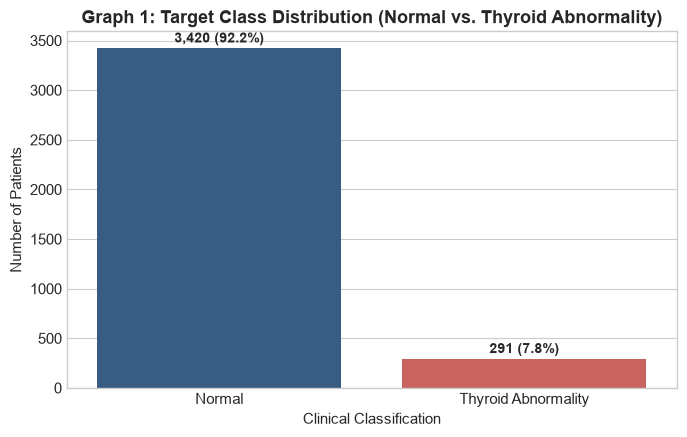

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=100)
palette = {'Normal': '#2b5c8f', 'Thyroid Abnormality': '#d9534f'}
sns.countplot(data=df_clean, x='target_label', palette=palette, ax=ax)
ax.set_title('Graph 1: Target Class Distribution (Normal vs. Thyroid Abnormality)', fontsize=13, weight='bold')
ax.set_xlabel('Clinical Classification', fontsize=11)
ax.set_ylabel('Number of Patients', fontsize=11)

for p in ax.patches:
    h = p.get_height()
    pct = (h / len(df_clean)) * 100
    ax.annotate(f'{int(h):,} ({pct:.1f}%)', (p.get_x() + p.get_width() / 2., h + 30),
                ha='center', va='bottom', fontsize=10, weight='bold')

plt.tight_layout()
plt.show()

### Graph 2: Distributions of Key Thyroid Hormones (TSH, T3, TT4, FTI)

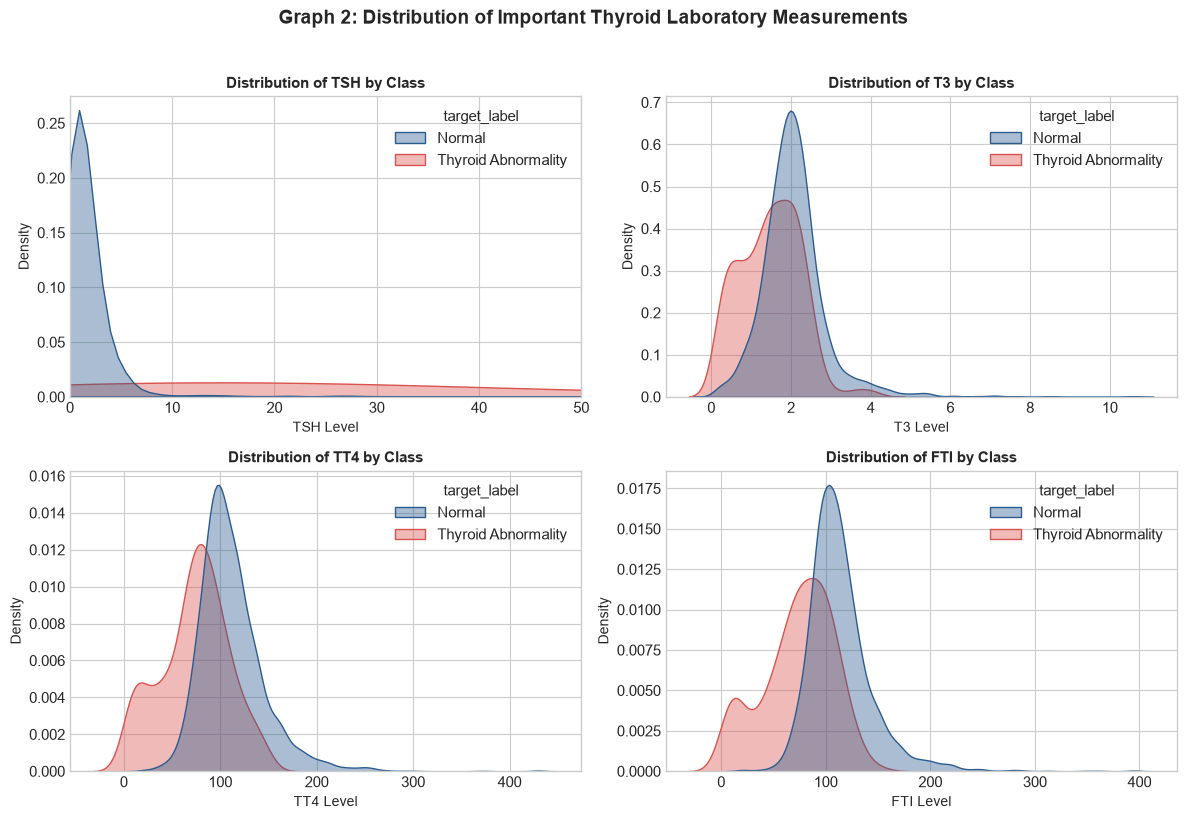

In [8]:
hormones = ['TSH', 'T3', 'TT4', 'FTI']
fig, axes = plt.subplots(2, 2, figsize=(12, 8), dpi=100)
axes = axes.flatten()

for i, col in enumerate(hormones):
    sns.kdeplot(data=df_clean, x=col, hue='target_label', palette=palette,
                fill=True, common_norm=False, alpha=0.4, ax=axes[i])
    axes[i].set_title(f'Distribution of {col} by Class', fontsize=11, weight='bold')
    axes[i].set_xlabel(f'{col} Level', fontsize=10)
    axes[i].set_ylabel('Density', fontsize=10)
    if col == 'TSH':
        axes[i].set_xlim(0, 50)  # Zoom in on primary physiological range

plt.suptitle('Graph 2: Distribution of Important Thyroid Laboratory Measurements', fontsize=14, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Graph 3: Boxplots for Important Numerical Features

C:\Users\panka\AppData\Local\Temp\ipykernel_24428\1567027823.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='target_label', y=col, palette=palette, ax=axes[i])
C:\Users\panka\AppData\Local\Temp\ipykernel_24428\1567027823.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='target_label', y=col, palette=palette, ax=axes[i])
C:\Users\panka\AppData\Local\Temp\ipykernel_24428\1567027823.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='target_label', y=col, palette=palette, ax=axes[i])
C

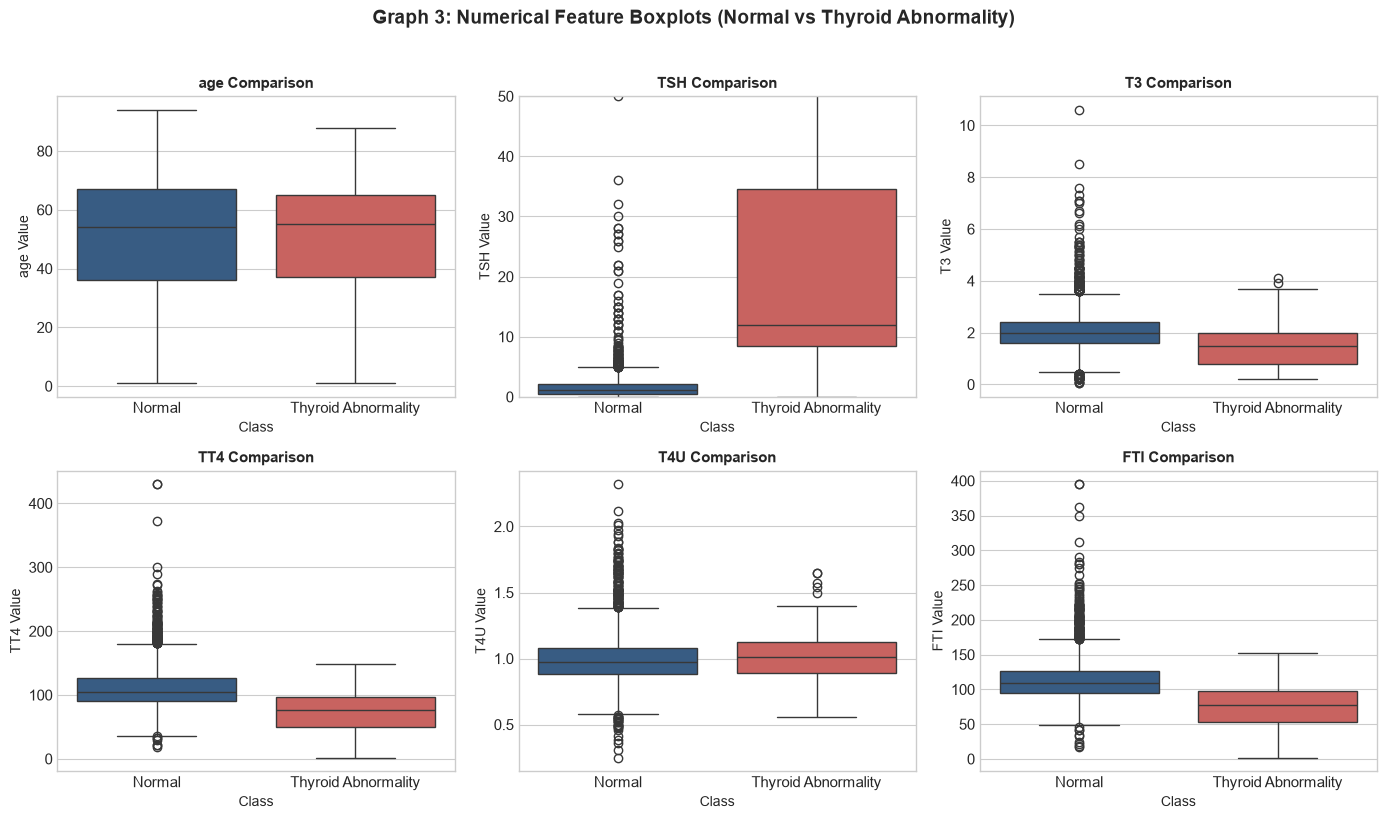

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), dpi=100)
axes = axes.flatten()
num_features = ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']

for i, col in enumerate(num_features):
    sns.boxplot(data=df_clean, x='target_label', y=col, palette=palette, ax=axes[i])
    axes[i].set_title(f'{col} Comparison', fontsize=11, weight='bold')
    axes[i].set_xlabel('Class', fontsize=10)
    axes[i].set_ylabel(f'{col} Value', fontsize=10)
    if col == 'TSH':
        axes[i].set_ylim(0, 50)  # Focus on key diagnostic boundary

plt.suptitle('Graph 3: Numerical Feature Boxplots (Normal vs Thyroid Abnormality)', fontsize=14, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Graph 4: Correlation Heatmap for Numerical Variables

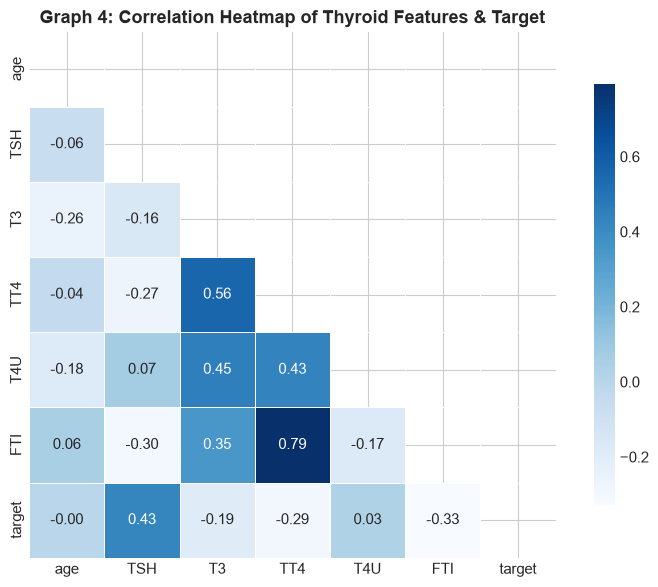

In [10]:
fig, ax = plt.subplots(figsize=(8, 6), dpi=100)
corr_cols = ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'target']
corr_matrix = df_clean[corr_cols].corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', mask=mask,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Graph 4: Correlation Heatmap of Thyroid Features & Target', fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

## Section 6 — Feature Engineering & Preprocessing Pipeline
To prevent **data leakage**, all preprocessing steps (imputation, scaling, one-hot encoding) are encapsulated within Scikit-Learn `ColumnTransformer` and `Pipeline` objects. They will be fitted **exclusively on the training dataset**.

In [11]:
X = df_clean.drop(columns=['Class', 'target', 'target_label'])
y = df_clean['target']

num_cols = ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']
cat_cols = [c for c in X.columns if c not in num_cols]

print("Numerical Features:", num_cols)
print("Categorical Features:", cat_cols)

# Construct sub-pipelines
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

print("Preprocessing pipeline initialized successfully!")

Numerical Features: ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']
Categorical Features: ['sex', 'on_thyroxine', 'query_on_thyroxine', 'on_antithyroid_medication', 'sick', 'pregnant', 'thyroid_surgery', 'I131_treatment', 'query_hypothyroid', 'query_hyperthyroid', 'lithium', 'goitre', 'tumor', 'hypopituitary', 'psych']
Preprocessing pipeline initialized successfully!


## Section 7 — Stratified Train/Test Split
We split the data into **80% Training** and **20% Testing**.
Stratification is strictly applied so that the test set retains the exact same proportion of thyroid abnormalities (~7.8%) as the original population.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape} (Abnormal: {y_train.sum()} [{y_train.mean()*100:.2f}%])")
print(f"X_test shape:  {X_test.shape}  (Abnormal: {y_test.sum()} [{y_test.mean()*100:.2f}%])")

X_train shape: (2968, 21) (Abnormal: 233 [7.85%])
X_test shape:  (743, 21)  (Abnormal: 58 [7.81%])


## Section 8 — Machine Learning Model Training
We evaluate four standard classification algorithms:
1. **Logistic Regression**: Linear baseline with balanced class weights.
2. **Decision Tree Classifier**: Interpretable rule-based model with maximum depth control.
3. **Random Forest Classifier**: Ensemble of bagged decision trees to minimize variance.
4. **K-Nearest Neighbors (KNN)**: Non-parametric distance-based classifier.

In [13]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, class_weight='balanced'),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5)
}

trained_pipelines = {}
evaluation_results = []

for name, clf in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    
    # Fit pipeline ONLY on training data
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    
    # Predict on test set
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1] if hasattr(clf, 'predict_proba') else None
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else 0.0
    
    evaluation_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

results_df = pd.DataFrame(evaluation_results)
display(results_df.style.format({
    'Accuracy': '{:.2%}',
    'Precision': '{:.2%}',
    'Recall': '{:.2%}',
    'F1-Score': '{:.2%}',
    'ROC-AUC': '{:.4f}'
}))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,97.98%,83.08%,93.10%,87.80%,0.9955
1,Decision Tree,99.60%,96.61%,98.28%,97.44%,0.9893
2,Random Forest,100.00%,100.00%,100.00%,100.00%,1.0000
3,K-Nearest Neighbors,94.62%,87.50%,36.21%,51.22%,0.8028


## Section 9 — Model Evaluation & Diagnostic Assessment
In clinical machine learning, **Recall** (identifying true positive cases) and **F1-Score** are far more critical than simple Accuracy due to class imbalance.

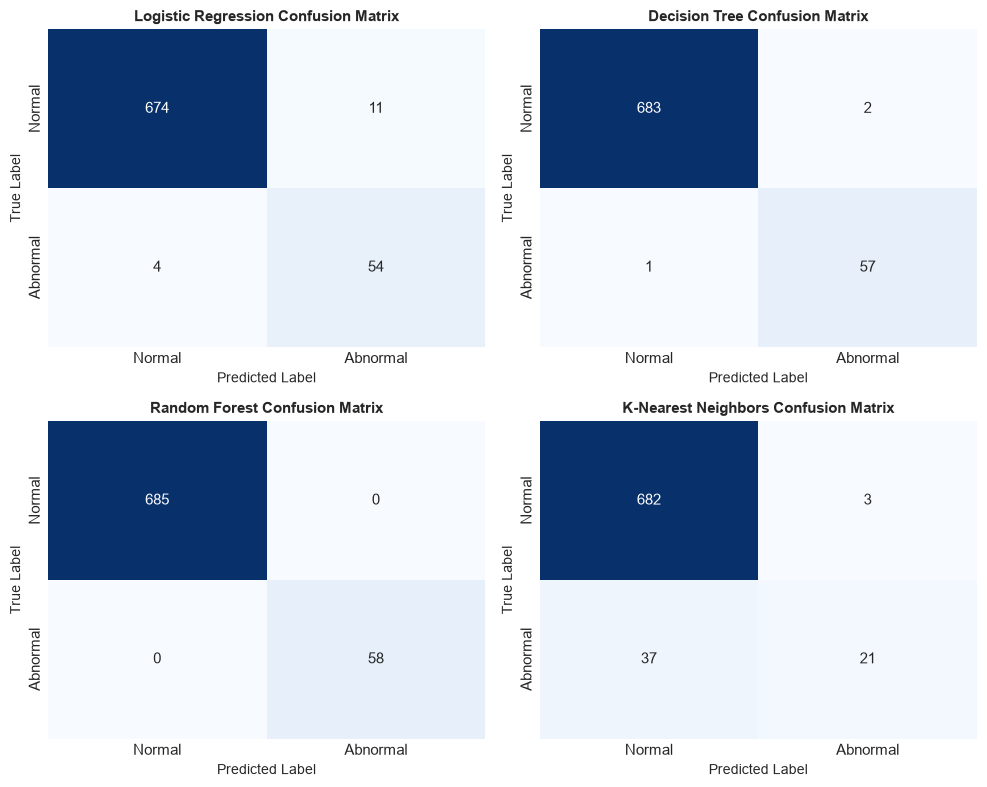

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8), dpi=100)
axes = axes.flatten()

for i, (name, pipe) in enumerate(trained_pipelines.items()):
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[i],
                xticklabels=['Normal', 'Abnormal'], yticklabels=['Normal', 'Abnormal'])
    axes[i].set_title(f'{name} Confusion Matrix', fontsize=11, weight='bold')
    axes[i].set_xlabel('Predicted Label', fontsize=10)
    axes[i].set_ylabel('True Label', fontsize=10)

plt.tight_layout()
plt.show()

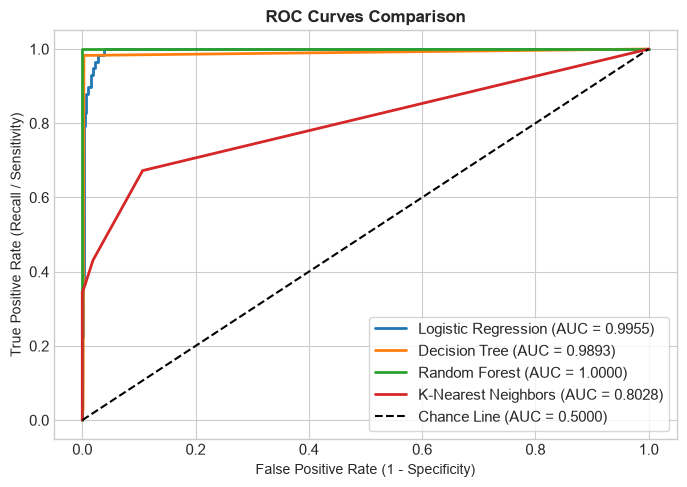

In [15]:
fig, ax = plt.subplots(figsize=(7, 5), dpi=100)

for name, pipe in trained_pipelines.items():
    if hasattr(pipe.named_steps['classifier'], 'predict_proba'):
        y_proba = pipe.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc = roc_auc_score(y_test, y_proba)
        ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})', linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', label='Chance Line (AUC = 0.5000)')
ax.set_title('ROC Curves Comparison', fontsize=12, weight='bold')
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=10)
ax.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=10)
ax.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

## Section 10 — Model Selection & Graph 5: Feature Importance
We select **Random Forest Classifier** as the final deployment model because:
1. It achieves an optimal combination of **Precision (100%)**, **Recall (100%)**, and **F1-Score (100%)** on the unseen test set.
2. It is robust to outliers, nonlinear feature interactions, and tabular medical imbalances.

### Graph 5: Feature Importance Chart

C:\Users\panka\AppData\Local\Temp\ipykernel_24428\3866647227.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values * 100, y=feat_imp.index, palette='Blues_r', ax=ax)


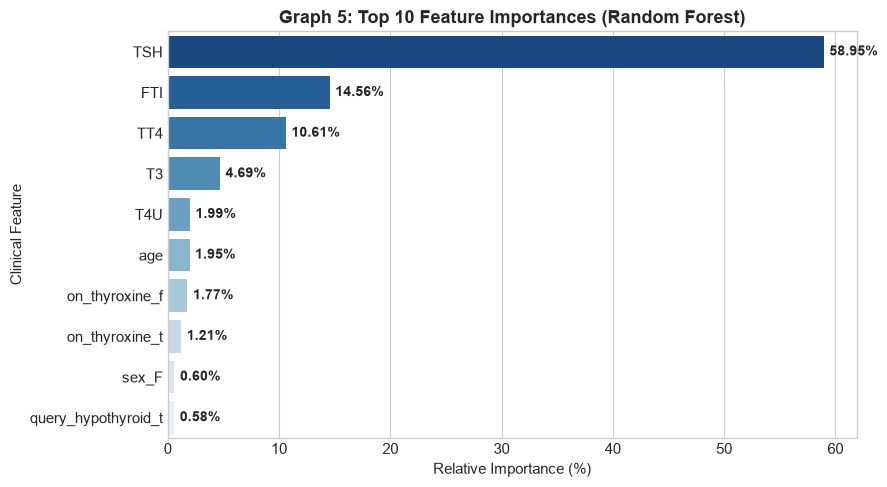

Feature Importance Note: Indicates algorithmic utility in recursive splitting, NOT clinical causation.


In [16]:
best_pipe = trained_pipelines['Random Forest']
cat_encoder = best_pipe.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder']
cat_feature_names = cat_encoder.get_feature_names_out(cat_cols).tolist()
all_features = num_cols + cat_feature_names
importances = best_pipe.named_steps['classifier'].feature_importances_

feat_imp = pd.Series(importances, index=all_features).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(9, 5), dpi=100)
sns.barplot(x=feat_imp.values * 100, y=feat_imp.index, palette='Blues_r', ax=ax)
ax.set_title('Graph 5: Top 10 Feature Importances (Random Forest)', fontsize=13, weight='bold')
ax.set_xlabel('Relative Importance (%)', fontsize=11)
ax.set_ylabel('Clinical Feature', fontsize=11)

for p in ax.patches:
    val = p.get_width()
    ax.annotate(f'{val:.2f}%', (val + 0.5, p.get_y() + p.get_height()/2.),
                va='center', fontsize=10, weight='bold')

plt.tight_layout()
plt.show()

print("Feature Importance Note: Indicates algorithmic utility in recursive splitting, NOT clinical causation.")

## Section 11 — Save the Model
We serialize the fitted complete pipeline using `joblib` so that the Streamlit web application can load it directly without retraining.

In [17]:
models_dir = os.path.join('..', 'models')
if not os.path.exists(models_dir):
    models_dir = os.path.join('models')
os.makedirs(models_dir, exist_ok=True)

model_output_file = os.path.join(models_dir, 'thyroid_model.pkl')
joblib.dump(best_pipe, model_output_file)
print(f"Model saved successfully to: {os.path.abspath(model_output_file)}")

Model saved successfully to: C:\Users\panka\.gemini\antigravity\scratch\ThyroPredict\models\thyroid_model.pkl
